# Step 4b: Device 1 drain current, model against the paper's Fig. 6(a) and Fig. 7(a)

- **Model [P]:** Eq. (17) from `current.py`, with V_DSAT built from q·n/C_g″ [DEVIATION] and V_OFF = −1.26 V. There is **no access resistance yet**, so the model should come out above the measurement.
- **Channel charge n (4c):** the exact n (root finding) [DEVIATION, temporary]. The closed-form n_total (Eqs. 9, 11, 14, 15) is drawn thin in panel (b) to show the three g_M glitches it causes.
- **Paper [P]:** measured points ([11], CW) and the paper's own model line, read from the PDF's vectors.
- Panels: (a) I_D against V_GS at V_DS = 10 V, (b) g_M = dI_D/dV_GS, (c) output curves for V_GS = −1 … 3 V.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from current import ids, V_OFF_TCADP

def load(name):
    """Read one paper_data CSV (2 comment lines + 1 header line) into a numpy array."""
    return np.loadtxt(f"paper_data/{name}.csv", delimiter=",", skiprows=3)

id_meas, gm_meas = load("fig6a_measured_ID"), load("fig6a_measured_gm")
id_pmod, gm_pmod = load("fig6a_paper_model_ID"), load("fig6a_paper_model_gm")
out_meas, out_pmod = load("fig7a_measured"), load("fig7a_paper_model")

V = np.linspace(-3.0, 3.0, 601)              # V_GS grid, 10 mV steps
I_model = ids(V, 10.0) * 1e3                 # mA, at V_DS = 10 V
gm_model = np.gradient(I_model, V)           # mS (mA per V)
I_compact = ids(V, 10.0, charge="compact") * 1e3       # same, with the closed-form n_total
gm_compact = np.gradient(I_compact, V)

VGS_FAMILY = np.arange(-1.0, 3.01, 0.5)      # the nine Fig. 7(a) curves
VD = np.linspace(0.0, 10.0, 201)
I_out = {vg: ids(vg, VD) * 1e3 for vg in VGS_FAMILY}
print(f"V_OFF = {V_OFF_TCADP:+.3f} V; model ready: {len(V)} V_GS points, {len(VGS_FAMILY)} output curves")

V_OFF = -1.260 V; model ready: 601 V_GS points, 9 output curves


In [2]:
def at(curve, x):
    """Value of a curve (column 0 = x, column 1 = y) at x, by straight-line interpolation."""
    return np.interp(x, curve[:, 0], curve[:, 1])

def out_at(data, vg, vd):
    """Output-curve current at (V_GS, V_DS) from a Fig. 7(a) file (columns V_GS, V_DS, I_D)."""
    s = data[data[:, 0] == vg]
    return np.interp(vd, s[:, 1], s[:, 2])

model = np.column_stack([V, I_model])
model_gm = np.column_stack([V, gm_model])
rows = [("I_D at V_GS = 0 V (mA)",         at(id_meas, 0.0), at(id_pmod, 0.0), at(model, 0.0)),
        ("I_D at V_GS = +3 V (mA)",        at(id_meas, 3.0), at(id_pmod, 3.0), at(model, 3.0)),
        ("g_M peak (mS)",                  gm_meas[:, 1].max(), gm_pmod[:, 1].max(), gm_model.max()),
        ("V_GS at the g_M peak (V)",       gm_meas[gm_meas[:, 1].argmax(), 0], gm_pmod[gm_pmod[:, 1].argmax(), 0],
                                           V[gm_model.argmax()]),
        ("g_M at V_GS = +2.4 V (mS)",      at(gm_meas, 2.4), at(gm_pmod, 2.4), at(model_gm, 2.4)),
        ("I_D at V_GS = 3, V_DS = 1 V (mA)", out_at(out_meas, 3.0, 1.0), out_at(out_pmod, 3.0, 1.0), ids(3.0, 1.0) * 1e3)]
print(f"{'':34s}{'measured':>10s}{'paper model':>13s}{'our model':>11s}")
for name, a, b, c in rows:
    print(f"{name:34s}{a:10.2f}{b:13.2f}{c:11.2f}")

                                    measured  paper model  our model
I_D at V_GS = 0 V (mA)                 39.05        39.51      48.06
I_D at V_GS = +3 V (mA)               151.90       152.05     241.47
g_M peak (mS)                          42.59        42.52      66.24
V_GS at the g_M peak (V)                0.30         0.15       1.18
g_M at V_GS = +2.4 V (mS)              33.41        33.26      63.98
I_D at V_GS = 3, V_DS = 1 V (mA)       36.62        36.58     193.92


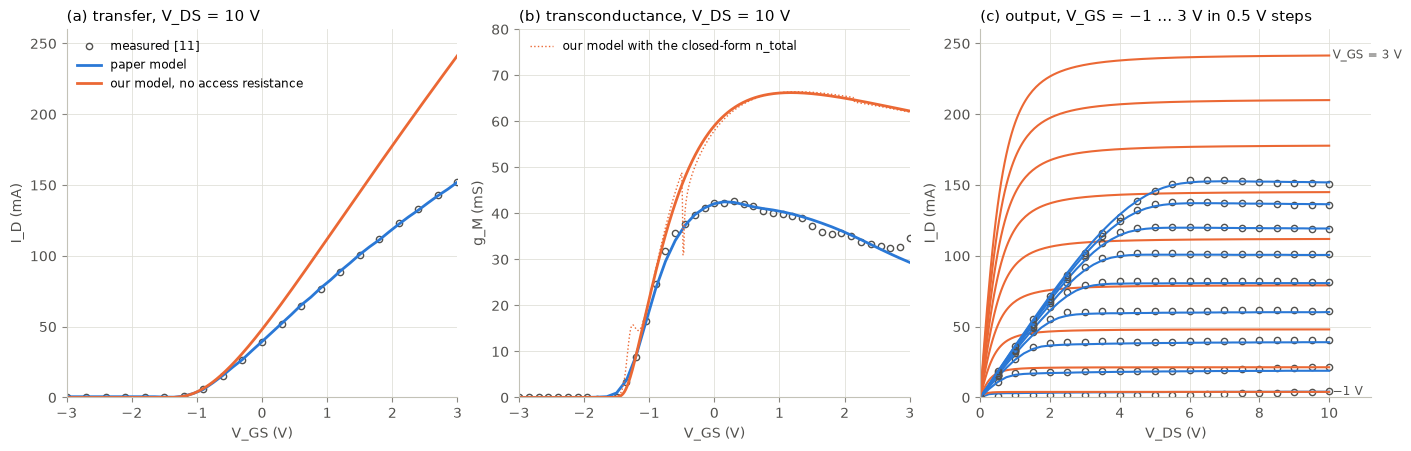

In [3]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK, "ytick.labelcolor": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
meas_style = dict(ls="none", marker="o", mfc="none", mec=INK, ms=4.5)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)

ax1.plot(id_meas[:, 0], id_meas[:, 1], **meas_style, label="measured [11]")
ax1.plot(id_pmod[:, 0], id_pmod[:, 1], color=BLUE, lw=2, label="paper model")
ax1.plot(V, I_model, color=ORANGE, lw=2, label="our model, no access resistance")
ax1.set_ylabel("I_D (mA)"); ax1.set_ylim(0, 260)
ax1.set_title("(a) transfer, V_DS = 10 V", loc="left", fontsize=11)
ax1.legend(loc="upper left", fontsize=8.5)

ax2.plot(gm_meas[:, 0], gm_meas[:, 1], **meas_style)
ax2.plot(gm_pmod[:, 0], gm_pmod[:, 1], color=BLUE, lw=2)
ax2.plot(V, gm_compact, color=ORANGE, lw=1, ls=":", label="our model with the closed-form n_total")
ax2.plot(V, gm_model, color=ORANGE, lw=2)
ax2.legend(loc="upper left", fontsize=8.5)
ax2.set_ylabel("g_M (mS)"); ax2.set_ylim(0, 80)
ax2.set_title("(b) transconductance, V_DS = 10 V", loc="left", fontsize=11)

for ax in (ax1, ax2):
    ax.set_xlim(-3, 3); ax.set_xlabel("V_GS (V)")

for vg in VGS_FAMILY:
    s = out_meas[out_meas[:, 0] == vg]
    ax3.plot(s[:, 1], s[:, 2], **meas_style)
    s = out_pmod[out_pmod[:, 0] == vg]
    ax3.plot(s[:, 1], s[:, 2], color=BLUE, lw=1.5)
    ax3.plot(VD, I_out[vg], color=ORANGE, lw=1.5)
ax3.text(10.1, I_out[3.0][-1], "V_GS = 3 V", va="center", fontsize=8.5, color=INK)
ax3.text(10.1, I_out[-1.0][-1], "−1 V", va="center", fontsize=8.5, color=INK)
ax3.set_xlim(0, 11.2); ax3.set_ylim(0, 260)
ax3.set_xlabel("V_DS (V)"); ax3.set_ylabel("I_D (mA)")
ax3.set_title("(c) output, V_GS = −1 … 3 V in 0.5 V steps", loc="left", fontsize=11)

for ax in (ax1, ax2, ax3):
    ax.grid(True, color=GRID, lw=0.6)
fig.savefig("figures/step4b_fig6a_fig7a.png", dpi=200)
plt.show()